# Tarea 1 · Bonificación — Buscador semántico y sesgo comparativo

1. **Buscador semántico:** embeddings de los 400 titulares con `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2` y recuperación por **similitud coseno**.
2. **Análisis de sesgo (opción C):** se emparejan titulares de *La República* y *El Comercio* que cuentan **la misma noticia**, se compara cómo titula cada medio y si el clasificador BETO **cambia su predicción** según el medio. Se complementa con el desempeño del clasificador por medio en el test reservado.

In [1]:
import json, re
from pathlib import Path
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import torch
from sentence_transformers import SentenceTransformer
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score
from transformers import pipeline
import scraping as sc

pio.renderers.default = "plotly_mimetype+png"
pd.set_option("display.max_colwidth", 110)
SEED = 42
DATOS, MODELO = Path("datos"), Path("modelo")
EMB = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
DISPOSITIVO = "mps" if torch.backends.mps.is_available() else "cpu"

df = pd.read_csv(DATOS / "noticias.csv")
encoder = SentenceTransformer(EMB, device=DISPOSITIVO)
clf = pipeline("text-classification", model=str(MODELO), tokenizer=str(MODELO), top_k=None, device=DISPOSITIVO)

def predecir(titulares):
    out = clf(list(titulares), batch_size=32)
    mejor = [max(r, key=lambda x: x["score"]) for r in out]
    return [m["label"] for m in mejor], [m["score"] for m in mejor]

W1018 12:14:42.713000 20220 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

## 1. Buscador semántico

Se codifica solo el **titular** (igual que la consulta) y los vectores se normalizan, de modo que el producto punto es la similitud coseno. Los embeddings se guardan en `datos/embeddings_titulares.npy` para que el dashboard no tenga que recalcularlos.

In [2]:
E = encoder.encode(df["titular"].tolist(), normalize_embeddings=True, batch_size=64, show_progress_bar=False)
np.save(DATOS / "embeddings_titulares.npy", E.astype(np.float32))
print(E.shape)

def buscar(consulta, k=5):
    q = encoder.encode([consulta], normalize_embeddings=True)[0]
    sim = E @ q
    top = np.argsort(-sim)[:k]
    return df.iloc[top][["titular", "medio", "etiqueta", "fecha"]].assign(similitud=sim[top].round(3))

for consulta in ["Congreso debate retiro de fondos de pensiones",
                 "Selección peruana juega por las Eliminatorias",
                 "Nuevo modelo de inteligencia artificial"]:
    print("Consulta:", consulta)
    display(buscar(consulta))

(400, 384)
Consulta: Congreso debate retiro de fondos de pensiones


,titular,medio,etiqueta,fecha,similitud
359,Marcha por el retiro AFP y contra la reforma de pensiones: afiliados exigen liberación de 4 UIT,La Republica,economia,2025-09-13,0.615
309,Congreso propone noveno retiro de AFP de hasta S/22.000 y reembolso total para herederos,La Republica,economia,2026-02-20,0.587
358,Jorge Torres Saravia: renunciaron las integrantes de la comisión ad hoc del Congreso que lo investigó,La Republica,politica,2025-01-08,0.489
78,Ausencia de senadores de izquierda y aliados frustra debate y votación de facultades: los entretelones de ...,El Comercio,politica,2026-10-16,0.487
226,Las nuevas bancadas ‘cascarón’: Votaciones en temas oficialistas muestran fisuras en grupos del Congreso,El Comercio,politica,2026-10-14,0.486


Consulta: Selección peruana juega por las Eliminatorias


,titular,medio,etiqueta,fecha,similitud
316,Perú entre el lamento y la esperanza de clasificar al Mundial,La Republica,deportes,2025-09-01,0.788
288,Alianza Lima vs Rebaza Acosta EN VIVO: hora y dónde ver la fecha 1 de la Liga Peruana de Vóley,El Comercio,deportes,2026-10-18,0.782
79,Perú va por el milagro ante Uruguay por Eliminatorias: ¿cuándo fue la última vez que ganamos en Montevideo?,La Republica,deportes,2025-08-31,0.780
84,Programación de la fecha 17 de las Eliminatorias 2025: posiciones de Perú y demás selecciones en la tabla,La Republica,deportes,2025-09-01,0.778
132,"Perú vs Uruguay: fecha, hora y canal confirmado de la penúltima jornada por Eliminatorias 2026",La Republica,deportes,2025-09-01,0.767


Consulta: Nuevo modelo de inteligencia artificial


,titular,medio,etiqueta,fecha,similitud
58,"Epic, creadora de Fortnite, da un “giro” hacia el uso de la IA",El Comercio,ciencia_tecnologia,2026-10-13,0.501
292,"Maia 300, el nuevo chip de Microsoft para escalar su infraestructura de IA que llegará en 2027",El Comercio,ciencia_tecnologia,2026-10-13,0.364
81,Trump quiere llamar “superinteligencia” a la IA y amenaza con tratar como “enemigo” a quien no lo haga,El Comercio,ciencia_tecnologia,2026-10-09,0.363
156,"De consultar saldos a delegar operaciones, ¿cómo cambiará la banca con la IA hacia 2030?",El Comercio,economia,2026-10-16,0.362
393,Apple prepara una pantalla con IA para controlar el hogar y un diseño que revive un clásico de hace 24 años,El Comercio,ciencia_tecnologia,2026-10-06,0.353


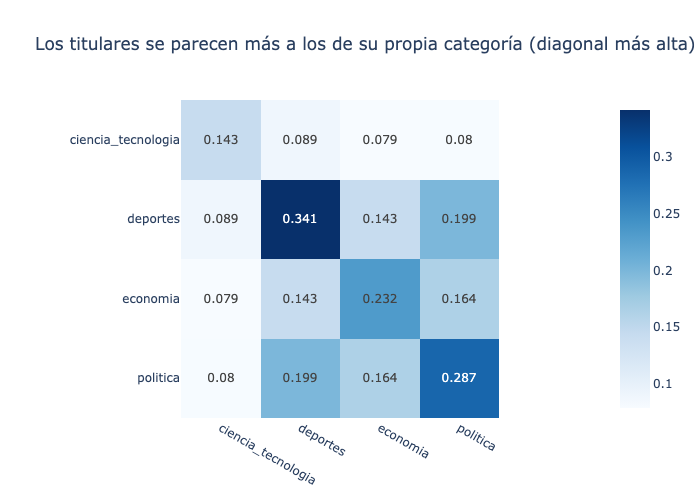

In [3]:
# ¿Los embeddings capturan la categoría? Similitud media intra vs. entre categorías
S = E @ E.T
etq = df["etiqueta"].values
cats = sorted(df["etiqueta"].unique())
mat = pd.DataFrame([[S[np.ix_(etq == a, etq == b)].mean() for b in cats] for a in cats], index=cats, columns=cats).round(3)
fig = px.imshow(mat, text_auto=True, color_continuous_scale="Blues",
                title="Los titulares se parecen más a los de su propia categoría (diagonal más alta)")
fig.show()

## 2. Sesgo comparativo: la misma noticia en ambos medios

**Universo:** todas las notas recolectadas desde el 5 de octubre de 2026 (El Comercio completo + RSS actuales de La República, más el RSS `home` de La República descargado para este análisis y guardado en `datos/raw/bonus/`).

**Regla de emparejamiento:** para cada titular de El Comercio se busca el más similar de La República; se acepta el par si **(a)** es el mejor match en ambas direcciones, **(b)** similitud coseno ≥ 0.82 y **(c)** las fechas difieren en ≤ 3 días. El umbral se fijó revisando a mano los candidatos: por encima de 0.82 todos los pares eran la misma noticia; por debajo empiezan a aparecer temas solo parecidos.

In [4]:
pool = pd.DataFrame(sc.cargar_raw())
home = pd.DataFrame(sc.parse_rss((sc.RAW / "bonus" / "lr_rss_home_actual.xml").read_bytes(), "La Republica", "home"))
pool = pd.concat([pool, home]).drop_duplicates("url")
pool["fecha_dt"] = pd.to_datetime(pool["fecha"], utc=True, format="mixed")
pool = pool[pool["fecha_dt"] >= "2026-10-05"]
ec = pool[pool.medio == "El Comercio"].reset_index(drop=True)
lr = pool[pool.medio == "La Republica"].reset_index(drop=True)
print("El Comercio:", len(ec), "| La República:", len(lr))

Ec = encoder.encode(ec["titular"].tolist(), normalize_embeddings=True)
Lr = encoder.encode(lr["titular"].tolist(), normalize_embeddings=True)
S2 = Ec @ Lr.T
filas = []
for i in range(len(ec)):
    j = S2[i].argmax()
    dias = abs((ec.fecha_dt[i] - lr.fecha_dt[j]).days)
    if S2[:, j].argmax() == i and S2[i, j] >= 0.82 and dias <= 3:
        filas.append({"similitud": round(float(S2[i, j]), 3), "dias": dias,
                      "titular_ec": ec.titular[i], "titular_lr": lr.titular[j],
                      "url_ec": ec.url[i], "url_lr": lr.url[j]})
pares = pd.DataFrame(filas).sort_values("similitud", ascending=False).reset_index(drop=True)
print(len(pares), "pares de la misma noticia")
pares[["similitud", "dias", "titular_ec", "titular_lr"]]

El Comercio: 399 | La República: 208


13 pares de la misma noticia


,similitud,dias,titular_ec,titular_lr
0,0.969,0,Alianza Lima vs Rebaza Acosta EN VIVO: hora y dónde ver la fecha 1 de la Liga Peruana de Vóley,Alianza Lima vs Rebaza Acosta EN VIVO: hora y canal del partido por la fecha 1 de la Liga Peruana de Vóley...
1,0.964,0,Halloween y Día de la Canción Criolla: celebraciones aumentarían hasta en 12% ventas de las pymes,Halloween y Día de la Canción Criolla: pymes esperan elevar sus ventas hasta 12% en octubre
2,0.961,1,¡Impresionante! Perú conquistó catorce medallas en el ALAS Global Tours de Puerto Rico,¡Perú conquista 14 medallas en el ALAS Global Tours de Puerto Rico!
3,0.956,0,"Partidos de hoy, domingo 18 de octubre del 2026: hora, canales de televisión y dónde ver fútbol EN VIVO","Partidos de hoy, domingo 18 de octubre: horarios y canales para ver fútbol EN VIVO"
4,0.951,0,"Precio del dólar en Perú hoy, domingo 18 de octubre: cuál es el tipo de cambio del día","Precio del dólar hoy en Perú, domingo 18 de octubre: consulta el tipo de cambio para compra y venta"
5,0.949,1,Precio del dólar en Perú: cuál fue el tipo de cambio del sábado 17 de octubre,"Precio del dólar hoy en Perú, viernes 16 de octubre: consulta el tipo de cambio para compra y venta"
6,0.929,0,Sporting Cristal vs Comerciantes Unidos EN VIVO: sigue el partido por el Torneo Clausura 2026,Sporting Cristal vs Comerciantes Unidos EN VIVO: hora y canal del partido por la fecha 12 del Torneo Claus...
7,0.882,0,"Liga 1 MAX en directo, Universitario vs. Alianza Atlético por fecha 12 del Torneo Clausura de Liga 1",Alianza Atlético vs Universitario EN VIVO: hora y canal del partido por la fecha 12 del Torneo Clausura de...
8,0.851,1,"Tabla de posiciones, Liga 1 EN VIVO: repasa la tabla del Torneo Clausura y Acumulado",Tabla de posiciones Torneo Clausura y Acumulado de la Liga 1 2026: resultados de los partidos de la fecha 12
9,0.844,0,¡Triunfo en casa! Alianza Lima venció 3-1 a Atlético Grau en Matute | RESUMEN Y GOLES,Alianza Lima se hizo fuerte en Matute: venció 3-1 a Atlético Grau y se mantiene en la lucha por el Torneo ...


### ¿El clasificador cambia de categoría según el medio?

In [5]:
pares["pred_ec"], pares["prob_ec"] = predecir(pares["titular_ec"])
pares["pred_lr"], pares["prob_lr"] = predecir(pares["titular_lr"])
pares["misma_prediccion"] = pares["pred_ec"] == pares["pred_lr"]
pares["dif_prob"] = (pares["prob_lr"] - pares["prob_ec"]).round(3)
en_dataset = set(df["url"])
pares["en_dataset"] = pares["url_ec"].isin(en_dataset) | pares["url_lr"].isin(en_dataset)
print(f"Misma predicción en {pares.misma_prediccion.sum()}/{len(pares)} pares "
      f"({pares.misma_prediccion.mean():.0%}); {pares.en_dataset.sum()} pares tienen al menos un titular usado en el dataset.")
pares[["titular_ec", "pred_ec", "prob_ec", "titular_lr", "pred_lr", "prob_lr", "misma_prediccion"]].round(3)

Misma predicción en 13/13 pares (100%); 8 pares tienen al menos un titular usado en el dataset.


,titular_ec,pred_ec,prob_ec,titular_lr,pred_lr,prob_lr,misma_prediccion
0,Alianza Lima vs Rebaza Acosta EN VIVO: hora y dónde ver la fecha 1 de la Liga Peruana de Vóley,deportes,0.983,Alianza Lima vs Rebaza Acosta EN VIVO: hora y canal del partido por la fecha 1 de la Liga Peruana de Vóley...,deportes,0.983,True
1,Halloween y Día de la Canción Criolla: celebraciones aumentarían hasta en 12% ventas de las pymes,economia,0.823,Halloween y Día de la Canción Criolla: pymes esperan elevar sus ventas hasta 12% en octubre,economia,0.897,True
2,¡Impresionante! Perú conquistó catorce medallas en el ALAS Global Tours de Puerto Rico,deportes,0.974,¡Perú conquista 14 medallas en el ALAS Global Tours de Puerto Rico!,deportes,0.953,True
3,"Partidos de hoy, domingo 18 de octubre del 2026: hora, canales de televisión y dónde ver fútbol EN VIVO",deportes,0.982,"Partidos de hoy, domingo 18 de octubre: horarios y canales para ver fútbol EN VIVO",deportes,0.981,True
4,"Precio del dólar en Perú hoy, domingo 18 de octubre: cuál es el tipo de cambio del día",economia,0.968,"Precio del dólar hoy en Perú, domingo 18 de octubre: consulta el tipo de cambio para compra y venta",economia,0.970,True
5,Precio del dólar en Perú: cuál fue el tipo de cambio del sábado 17 de octubre,economia,0.962,"Precio del dólar hoy en Perú, viernes 16 de octubre: consulta el tipo de cambio para compra y venta",economia,0.970,True
6,Sporting Cristal vs Comerciantes Unidos EN VIVO: sigue el partido por el Torneo Clausura 2026,deportes,0.982,Sporting Cristal vs Comerciantes Unidos EN VIVO: hora y canal del partido por la fecha 12 del Torneo Claus...,deportes,0.982,True
7,"Liga 1 MAX en directo, Universitario vs. Alianza Atlético por fecha 12 del Torneo Clausura de Liga 1",deportes,0.983,Alianza Atlético vs Universitario EN VIVO: hora y canal del partido por la fecha 12 del Torneo Clausura de...,deportes,0.983,True
8,"Tabla de posiciones, Liga 1 EN VIVO: repasa la tabla del Torneo Clausura y Acumulado",deportes,0.981,Tabla de posiciones Torneo Clausura y Acumulado de la Liga 1 2026: resultados de los partidos de la fecha 12,deportes,0.981,True
9,¡Triunfo en casa! Alianza Lima venció 3-1 a Atlético Grau en Matute | RESUMEN Y GOLES,deportes,0.981,Alianza Lima se hizo fuerte en Matute: venció 3-1 a Atlético Grau y se mantiene en la lucha por el Torneo ...,deportes,0.983,True


### ¿Cómo titula cada medio? Rasgos de redacción

In [6]:
def rasgos(t):
    return {"caracteres": len(t), "palabras": len(t.split()),
            "exclamacion": "¡" in t or "!" in t, "pregunta": "¿" in t or "?" in t,
            "cita_textual": bool(re.search(r'[“"«]', t)),
            "mayusculas_enfaticas": bool(re.search(r"[A-ZÁÉÍÓÚÑ]{2,}\s+[A-ZÁÉÍÓÚÑ]{2,}", t))}

comp = []
for medio, col in [("El Comercio", "titular_ec"), ("La Republica", "titular_lr")]:
    r = pd.DataFrame([rasgos(t) for t in pares[col]]).mean()
    comp.append(r.rename(medio))
rasgos_pares = pd.concat(comp, axis=1).round(2)
rasgos_pares

,El Comercio,La Republica
caracteres,91.46,107.62
palabras,16.62,20.00
exclamacion,0.15,0.08
pregunta,0.00,0.00
cita_textual,0.08,0.08
mayusculas_enfaticas,0.31,0.31


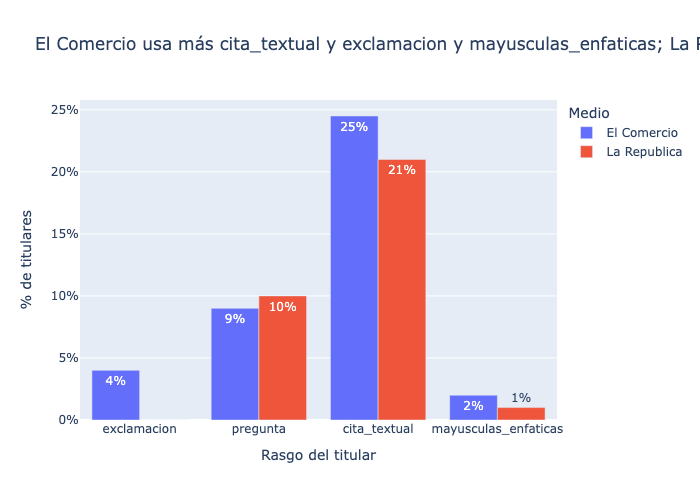

,El Comercio,La Republica
caracteres,100.395,105.190
palabras,16.820,17.285
exclamacion,0.040,0.000
pregunta,0.090,0.100
cita_textual,0.245,0.210
mayusculas_enfaticas,0.020,0.010


In [7]:
# Los mismos rasgos en todo el dataset (400) para ver si el patrón se sostiene
todo = pd.concat([pd.DataFrame([rasgos(t) for t in df.loc[df.medio == m, "titular"]]).mean().rename(m)
                  for m in ["El Comercio", "La Republica"]], axis=1).round(3)
largo = todo.loc[["caracteres", "palabras"]]
prop = todo.drop(["caracteres", "palabras"]).reset_index(names="rasgo").melt(id_vars="rasgo", var_name="medio", value_name="proporcion")
mas = prop.loc[prop.groupby("rasgo")["proporcion"].idxmax()]
fig = px.bar(prop, x="rasgo", y="proporcion", color="medio", barmode="group", text_auto=".0%",
             title=(f"El Comercio usa más {' y '.join(mas[mas.medio=='El Comercio'].rasgo)}; "
                    f"La República, más {' y '.join(mas[mas.medio=='La Republica'].rasgo)} (diferencias pequeñas)"),
             labels={"rasgo": "Rasgo del titular", "proporcion": "% de titulares", "medio": "Medio"})
fig.update_yaxes(tickformat=".0%")
fig.show()
todo

## 3. Cómo titula cada diario

Dos preguntas sobre los **400 titulares** (50 por sección y diario, así que las secciones están balanceadas):

1. **¿Qué palabras usa más cada diario dentro de una misma sección?** Log-odds con suavizado (+1) entre la frecuencia relativa de cada palabra en La República y en El Comercio; se ignoran palabras vacías y palabras de menos de 4 letras.
2. **¿Se puede adivinar el diario solo con el titular?** TF-IDF (unigramas y bigramas) + regresión logística, validación cruzada estratificada de 5 particiones; el azar es 50 %.

**Advertencia:** La República proviene del histórico de sus RSS (dic. 2024 – oct. 2026) y El Comercio de octubre de 2026, así que parte de las diferencias puede deberse a la **época** (otros temas, otros nombres) y no solo al estilo. Por eso se repite la prueba 2 en la ventana común (5–18 de octubre), aunque ahí La República solo tiene unas 56 notas.

In [8]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline

VACIAS = set("""para sobre este esta estos estas como cómo cuál cuáles cuando cuándo donde dónde desde hasta
entre tras ante bajo contra según sin durante mientras porque pero también tiene tienen será serán fue fueron
está están hace hacen puede pueden todo todos toda todas otro otra otros otras más menos muy hoy años año
perú peruano peruana peruanos qué quién quiénes nuevo nueva nuevos nuevas luego tras cada dice dijo""".split())

def palabras_caracteristicas(d, n=8):
    cv = CountVectorizer(token_pattern=r"[a-záéíóúñü]{4,}", min_df=2,
                         stop_words=sorted(VACIAS))
    M = cv.fit_transform(d["titular"].str.lower())
    voc = np.array(cv.get_feature_names_out())
    lr = np.asarray(M[(d["medio"] == "La Republica").values].sum(0)).ravel() + 1
    ec = np.asarray(M[(d["medio"] == "El Comercio").values].sum(0)).ravel() + 1
    lo = np.log(lr / lr.sum()) - np.log(ec / ec.sum())
    orden = np.argsort(lo)
    sel = np.r_[orden[:n], orden[-n:]]
    return pd.DataFrame({"palabra": voc[sel], "log_odds": lo[sel].round(3),
                         "usos_lr": lr[sel] - 1, "usos_ec": ec[sel] - 1,
                         "diario": np.where(lo[sel] > 0, "La Republica", "El Comercio")})

palabras = pd.concat([palabras_caracteristicas(g).assign(etiqueta=etq) for etq, g in df.groupby("etiqueta")],
                     ignore_index=True)
for etq, g in palabras.groupby("etiqueta"):
    print(f"{etq:20s} LR: {', '.join(g[g.diario=='La Republica'].sort_values('log_odds', ascending=False).palabra)}")
    print(f"{'':20s} EC: {', '.join(g[g.diario=='El Comercio'].sort_values('log_odds').palabra)}")

ciencia_tecnologia   LR: científicos, millones, solar, microplásticos, china, eclipse, mundo, estudio
                     EC: nobel, niño, física, google, lanza, datos, grand, hacia
deportes             LR: mundial, eliminatorias, club, victoria, christian, ruidíaz, cueva, zambrano
                     EC: video, real, liga, goles, laliga, canales, matute, open
economia             LR: retiro, revisa, fonavi, congreso, nación, aportes, noviembre, anuncia
                     EC: abre, street, wall, gran, inversión, mixto, inflación, banca
politica             LR: boluarte, candidatos, sánchez, derechos, dina, censura, pérez, nilo
                     EC: facultades, legislativas, gobierno, delegación, bancadas, comisión, senado, constitución


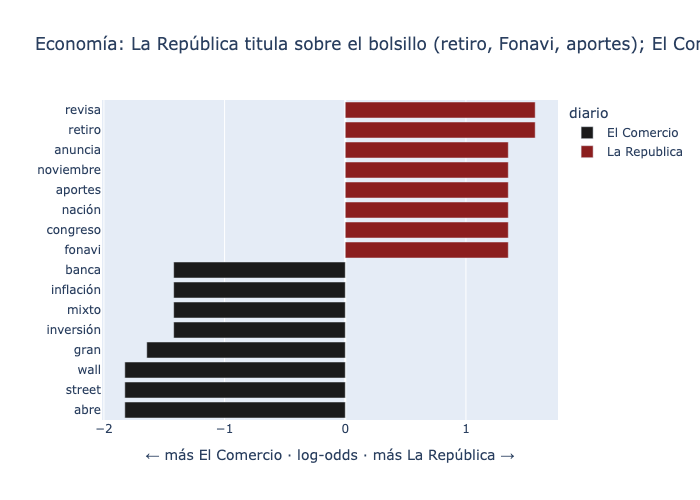

In [9]:
g = palabras[palabras.etiqueta == "economia"].sort_values("log_odds")
fig = px.bar(g, x="log_odds", y="palabra", color="diario", orientation="h",
             color_discrete_map={"La Republica": "#8B1E1E", "El Comercio": "#1A1A1A"},
             title="Economía: La República titula sobre el bolsillo (retiro, Fonavi, aportes); El Comercio, sobre los mercados (Wall Street, inversión, banca)",
             labels={"log_odds": "← más El Comercio · log-odds · más La República →", "palabra": ""})
fig.show()

In [10]:
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
modelo_medio = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2),
                             LogisticRegression(max_iter=2000, class_weight="balanced"))
acc_400 = cross_val_score(modelo_medio, df["titular"], df["medio"], cv=cv5, scoring="balanced_accuracy")
por_seccion = {etq: cross_val_score(modelo_medio, g["titular"], g["medio"], cv=cv5, scoring="balanced_accuracy").mean()
               for etq, g in df.groupby("etiqueta")}

# Ventana común: todas las notas del 5 al 18 de octubre en las 4 secciones (pool de la sección 2)
MAPEO = {"politica": "politica", "elecciones": "politica", "economia": "economia", "deportes": "deportes",
         "deporte-total": "deportes", "futbol-peruano": "deportes", "futbol-espanol": "deportes",
         "ciencia": "ciencia_tecnologia", "tecnologia": "ciencia_tecnologia"}
ventana = pool.assign(etiqueta=pool["url"].map(sc.seccion_desde_url).str.split("/").str[0].map(MAPEO)).dropna(subset=["etiqueta"])
acc_ventana = cross_val_score(modelo_medio, ventana["titular"], ventana["medio"], cv=cv5, scoring="balanced_accuracy")

print(f"¿Se adivina el diario? 400 titulares: {acc_400.mean():.1%} ± {acc_400.std():.1%} (azar 50%)")
print("Por sección:", {k: f"{v:.0%}" for k, v in por_seccion.items()})
print(f"Ventana común 5–18 oct ({ventana.medio.value_counts().to_dict()}): {acc_ventana.mean():.1%}")

¿Se adivina el diario? 400 titulares: 65.8% ± 2.7% (azar 50%)
Por sección: {'ciencia_tecnologia': '69%', 'deportes': '69%', 'economia': '64%', 'politica': '62%'}
Ventana común 5–18 oct ({'El Comercio': 384, 'La Republica': 56}): 54.9%


### Desempeño del clasificador por medio en el test reservado

Se reproduce exactamente el split de `02_clasificacion.ipynb` (mismo estrato y `random_state=42`).

In [11]:
estrato = df["etiqueta"] + "|" + df["medio"]
train, temp = train_test_split(df, test_size=0.30, stratify=estrato, random_state=SEED)
val, test = train_test_split(temp, test_size=0.50, stratify=estrato.loc[temp.index], random_state=SEED)
test = test.copy()
test["pred"], test["prob"] = predecir(test["titular"])
por_medio = test.groupby("medio").apply(lambda g: pd.Series({
    "n": len(g), "accuracy": accuracy_score(g.etiqueta, g.pred),
    "f1_macro": f1_score(g.etiqueta, g.pred, average="macro"),
    "confianza_media": g.prob.mean()}), include_groups=False).round(3)
por_medio

,n,accuracy,f1_macro,confianza_media
medio,,,,
El Comercio,31.0,0.935,0.931,0.913
La Republica,29.0,0.931,0.927,0.943


In [12]:
pares.to_csv(DATOS / "pares_misma_noticia.csv", index=False)
palabras.to_csv(DATOS / "palabras_caracteristicas.csv", index=False)
(DATOS / "sesgo_resumen.json").write_text(json.dumps({
    "acc_adivinar_diario_400": round(acc_400.mean(), 4), "acc_adivinar_diario_400_std": round(acc_400.std(), 4),
    "acc_adivinar_diario_por_seccion": {k: round(v, 4) for k, v in por_seccion.items()},
    "acc_adivinar_diario_ventana": round(acc_ventana.mean(), 4),
    "n_ventana": ventana.medio.value_counts().to_dict()}, indent=2, ensure_ascii=False))
test[["titular", "medio", "etiqueta", "pred", "prob"]].to_csv(DATOS / "predicciones_test.csv", index=False)
print("Guardados: pares_misma_noticia.csv, palabras_caracteristicas.csv, sesgo_resumen.json, predicciones_test.csv, embeddings_titulares.npy")

Guardados: pares_misma_noticia.csv, palabras_caracteristicas.csv, sesgo_resumen.json, predicciones_test.csv, embeddings_titulares.npy


## Conclusiones del bonus

**Buscador semántico.** Los embeddings multilingües recuperan noticias del mismo tema aunque no compartan palabras (p. ej. *"Selección peruana juega por las Eliminatorias"* → notas de *Perú vs. Uruguay*, similitud ≈ 0.78). La matriz de similitud muestra la diagonal más alta: el espacio de embeddings ya separa parcialmente las 4 categorías sin entrenamiento. Limitación: con 400 titulares, consultas de nicho devuelven similitudes bajas (< 0.5), es decir, "lo menos lejano", no necesariamente algo relevante.

**Sesgo comparativo (13 pares de la misma noticia).**
- El clasificador asigna **la misma categoría en 13/13 pares**: la categoría depende del hecho noticioso, no del medio. En el test reservado el desempeño también es parejo por medio (F1 0.93 en ambos).
- Donde sí cambia es la **confianza**: el caso más claro es la flor andina. El Comercio la titula *"…la bautizan en honor a Lionel Messi"* (deportes, 96 %) y La República *"Científicos descubren una nueva especie de flor albiceleste…"* (deportes, 77 %). El **encuadre** del titular (gancho de celebridad vs. encuadre científico) mueve la probabilidad 19 puntos; ambos son en realidad ciencia, así que el modelo aprendió que "Messi"/"albiceleste" ⇒ deportes.
- **Palabras características (400 titulares).** En *economía*, La República titula sobre el bolsillo del ciudadano (*retiro, Fonavi, aportes, Congreso*) y El Comercio sobre los mercados (*Wall Street, inversión, inflación, banca*). En *deportes*, La República se centra en el fútbol peruano y la selección (*Eliminatorias, Cueva, Ruidíaz*) y El Comercio en resultados y transmisiones (*video, goles, LaLiga, canales*). En *política*, El Comercio habla de instituciones (*facultades, Senado, comisión*) y La República de personajes y conflicto (*Boluarte, censura, candidatos*), aunque aquí pesa la diferencia de época.
- **¿Se adivina el diario por el titular?** Un modelo TF-IDF + regresión logística acierta el diario en el **66 %** de los casos (± 3 %, azar 50 %), algo más en deportes y ciencia (69 %) que en política (62 %). Hay un estilo propio **moderado**. En la ventana común (5–18 de octubre) baja a 55 %, pero con solo 56 notas de La República esa cifra es poco confiable: no se puede descartar que parte del 66 % venga de la época y no del estilo.
- Cautela: 13 pares es una muestra chica, concentrada en deportes y en servicios (dólar, partidos de hoy), y 8 de ellos tienen al menos un titular que el modelo vio en el dataset.